# DBSCAN hyperparameter optimization

## 1 Setup and data

In [39]:
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
IMG_DIR = "figs/tuned"
MODEL_DIR = "model"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
pd.set_option("display.max_columns", None)

red = "#c4515a"
grey = "#b9c4c0"
COLORS = ["#1d6c61", "#3e89ab", "#d08c3a", "#8a5aa3", "#5aa371", red,
          "#5a6fa3", "#9aa83e", "#a37a5a", "#4fb3a3"]
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6eeeb", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})


def save(name):
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

In [40]:
X = pd.read_csv("../data/H2_Cleaned_clustering.csv").to_numpy()
info = pd.read_csv("../data/H2_notdropped.csv")   # to describe clusters only
density_pca = joblib.load(f"{MODEL_DIR}/density_pca.joblib")   # first 5 principal components
Xd = density_pca.transform(X)
print("bookings:", len(X), " DBSCAN input:", Xd.shape)

bookings: 48990  DBSCAN input: (48990, 5)


DBSCAN runs on the 5 components, but the scores are computed on the 12 model columns

In [41]:
rng = np.random.default_rng(RANDOM_STATE)
S = np.sort(rng.choice(len(X), size=10_000, replace=False))   # the fixed silhouette sample


def evaluate(labels):
    clustered = labels >= 0                                    # noise (-1) is left out of the scores
    sizes = np.bincount(labels[clustered]) if clustered.any() else np.array([0])
    scores = {"clusters": labels.max() + 1,
              "noise %": (~clustered).mean() * 100,
              "smallest cluster %": sizes.min() / len(labels) * 100}
    if labels.max() < 1:                                       
        return scores
    s = S[clustered[S]]
    scores["silhouette"] = silhouette_score(X[s], labels[s])
    scores["davies_bouldin"] = davies_bouldin_score(X[clustered], labels[clustered])
    scores["calinski_harabasz"] = calinski_harabasz_score(X[clustered], labels[clustered])
    return scores

## 2 Baseline

In [42]:
baseline = joblib.load(f"{MODEL_DIR}/dbscan_baseline.joblib")
baseline_scores = evaluate(baseline.labels_)
pd.DataFrame([baseline_scores], index=["baseline (eps 0.5, min_samples 5)"]).round(3)

,clusters,noise %,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz
"baseline (eps 0.5, min_samples 5)",87,2.378,0.006,0.06,2.116,1129.091


## 3 Search space and optimization criteria

k-distance curves: for every booking, the distance to its `min_samples`-th nearest neighbour, sorted. For a given `eps`, the bookings left of where a curve crosses `eps` are core points. One curve per `min_samples` in the grid, and the shaded band is the `eps` range searched.

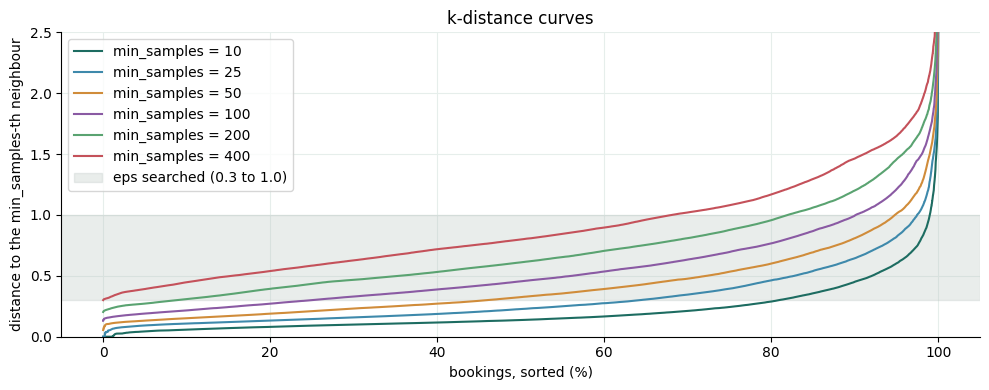

In [43]:
plt.figure(figsize=(10, 4))
for min_samples in [10, 25, 50, 100, 200, 400]:
    distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xd).kneighbors(Xd)
    plt.plot(np.linspace(0, 100, len(Xd)), np.sort(distances[:, -1]), label=f"min_samples = {min_samples}")
plt.axhspan(0.3, 1.0, color=grey, alpha=0.3, label="eps searched (0.3 to 1.0)")
plt.ylim(0, 2.5)
plt.xlabel("bookings, sorted (%)")
plt.ylabel("distance to the min_samples-th neighbour")
plt.title("k-distance curves")
plt.legend()
save("01_k_distance.png")

* No curve has a sharp knee before the last few percent, so there is no single natural `eps` to read off. That is why `eps` is searched.
* At 0.3, the curves for large `min_samples` are crossed by only a small share of the bookings, so most bookings would be noise.
* At 1.0, the curves for small `min_samples` are crossed by almost all bookings, so everything would chain into a few big clusters.

Search space
* `min_samples`: 10, 25, 50, 100, 200, 400
* `eps`: 0.3 to 1.0 in steps of 0.1, the band where the k distance curves go from few to almost all core points.

A configuration is valid only if:
* noise less than 15%, otherwise the scores improve just by throwing the hard bookings away
* 2 to 15 clusters (arbitrary number I set)
* every cluster has more than 0.5% of the bookings 

Criteria: silhouette (higher) and Davies–Bouldin (lower) are primary, Calinski–Harabasz (higher) is supporting

## 4 Grid search over eps and min_samples

In [ ]:
rows = []
for min_samples in [10, 25, 50, 100, 200, 400]:
    for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
        model = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit(Xd)
        rows.append({"eps": eps, "min_samples": min_samples, **evaluate(model.labels_)})

res = pd.DataFrame(rows)
res["valid"] = (res["noise %"] <= 15) & res["clusters"].between(2, 15) & (res["smallest cluster %"] >= 0.5)
print("valid configurations:", res["valid"].sum(), "of", len(res))

## 5 Choosing eps and min_samples

In [ ]:
valid = res[res["valid"]].drop(columns="valid")
valid["mean_rank"] = (valid["silhouette"].rank(ascending=False) + valid["davies_bouldin"].rank()) / 2
best = valid.loc[valid["mean_rank"].idxmin()]
BEST_EPS, BEST_MIN_SAMPLES = best["eps"], int(best["min_samples"])
print("best: eps", BEST_EPS, " min_samples", BEST_MIN_SAMPLES)
valid.sort_values("mean_rank").round(3)

best: eps 0.9  min_samples 200


,eps,min_samples,clusters,noise %,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,mean_rank
38,0.9,200,10,10.004,1.711,0.190,1.656,5630.902,1.5
47,1.0,400,7,12.752,1.190,0.130,1.636,4970.662,2.5
31,1.0,100,8,3.205,0.861,0.168,1.695,5264.594,3.0
39,1.0,200,7,7.032,0.676,0.165,1.681,5436.764,3.0


* Only 4 of 48 configurations are valid
* `eps` 0.9 with `min_samples` 200 has the best mean rank and the highest silhouette of the valid ones (0.190), with 10 clusters and 10% noise.

## 6 Baseline vs tuned

The final model is re-fit with the chosen settings, and its clusters are renumbered by size (C0 = largest). Noise stays −1.

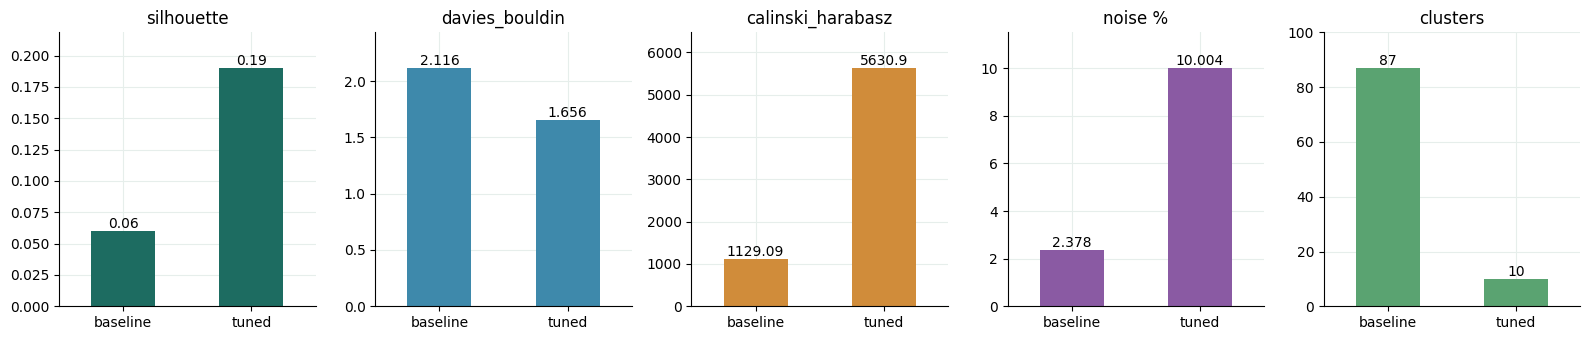

In [ ]:
final = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES, n_jobs=-1).fit(Xd)

order = pd.Series(final.labels_[final.labels_ >= 0]).value_counts().index   # old cluster ids, largest first
new_id = {old: new for new, old in enumerate(order)}
final.labels_ = np.array([new_id.get(old, -1) for old in final.labels_])     # noise (-1) stays -1
labels = final.labels_
C = [f"C{k}" for k in range(labels.max() + 1)]

comparison = pd.DataFrame([baseline_scores, evaluate(labels)], index=["baseline", "tuned"]).round(3)
axes = comparison[["silhouette", "davies_bouldin", "calinski_harabasz", "noise %", "clusters"]].plot.bar(
    subplots=True, layout=(1, 5), figsize=(16, 3.5), legend=False, rot=0)
for ax in axes.flat:
    ax.bar_label(ax.containers[0])     # value above each bar
    ax.margins(y=0.15)
save("02_baseline_vs_tuned.png")

* The tuned model is better on silhouette, Davies–Bouldin and Calinski–Harabasz.
* 87 clusters become 10, but 10% of the bookings are now noise instead of 2.4%.

## 7 Tuned clusters

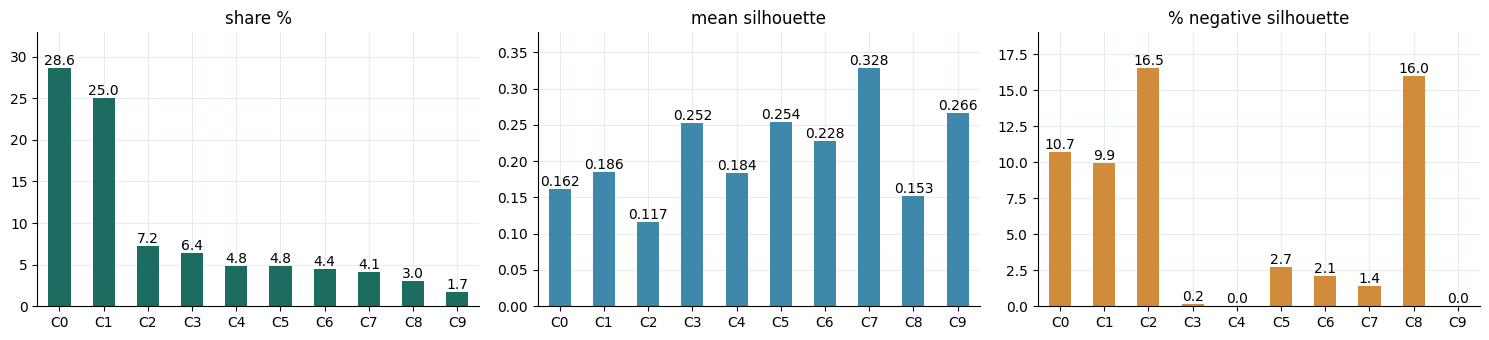

In [ ]:
s = S[labels[S] >= 0]                        # silhouette sample without the noise
sil = silhouette_samples(X[s], labels[s])
per_cluster = pd.DataFrame({
    "share %": [(labels == k).mean() * 100 for k in range(len(C))],
    "mean silhouette": [sil[labels[s] == k].mean() for k in range(len(C))],
    "% negative silhouette": [(sil[labels[s] == k] < 0).mean() * 100 for k in range(len(C))],
}, index=C)

axes = per_cluster.plot.bar(subplots=True, layout=(1, 3), figsize=(15, 3.5), legend=False, rot=0)
for ax in axes.flat:
    fmt = "%.3f" if ax.get_title() == "mean silhouette" else "%.1f"
    ax.bar_label(ax.containers[0], fmt=fmt)     # value above each bar
    ax.margins(y=0.15)
save("03_sizes_silhouette.png")

In [ ]:
names = C + ["noise"]
group = pd.Series(labels, name="cluster").map(lambda k: f"C{k}" if k >= 0 else "noise")
g = info.groupby(group)
prof = pd.DataFrame({
    "lead time (median days)": g["LeadTime"].median(),
    "nights (median)": g["TotalNights"].median(),
    "guests (mean)": g["TotalGuests"].mean(),
    "ADR (median)": g["ADR"].median(),
    "special requests (mean)": g["TotalOfSpecialRequests"].mean(),
    "repeat guests %": g["IsRepeatedGuest"].mean() * 100,
}).loc[names]
prof.round(1)

,lead time (median days),nights (median),guests (mean),ADR (median),special requests (mean),repeat guests %
cluster,,,,,,
C0,63.0,3.0,2.0,105.3,1.3,0.4
C1,66.0,3.0,2.0,96.3,0.0,0.5
C2,35.0,3.0,1.0,88.4,0.0,6.4
C3,84.0,3.0,3.0,137.7,1.6,0.1
C4,11.0,1.0,2.0,99.0,0.0,2.7
C5,20.0,1.0,2.0,108.0,1.3,2.3
C6,6.0,1.0,1.0,89.0,0.0,14.5
C7,90.0,3.0,3.0,142.6,0.0,0.0
C8,27.0,3.0,1.0,91.8,1.1,13.3


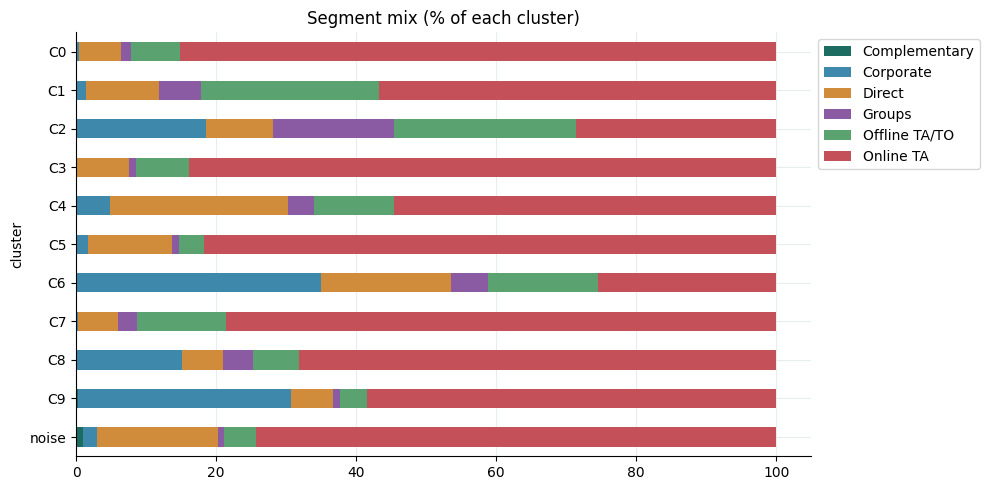

In [ ]:
mix = pd.crosstab(group, info["Segment"], normalize="index").loc[names] * 100
mix.plot.barh(stacked=True, figsize=(10, 5), title="Segment mix (% of each cluster)")
plt.gca().invert_yaxis()
plt.legend(bbox_to_anchor=(1, 1))
save("04_segment_mix.png")

## 8 PCA view

Noise is grey

variance explained by PC1 + PC2: 0.575


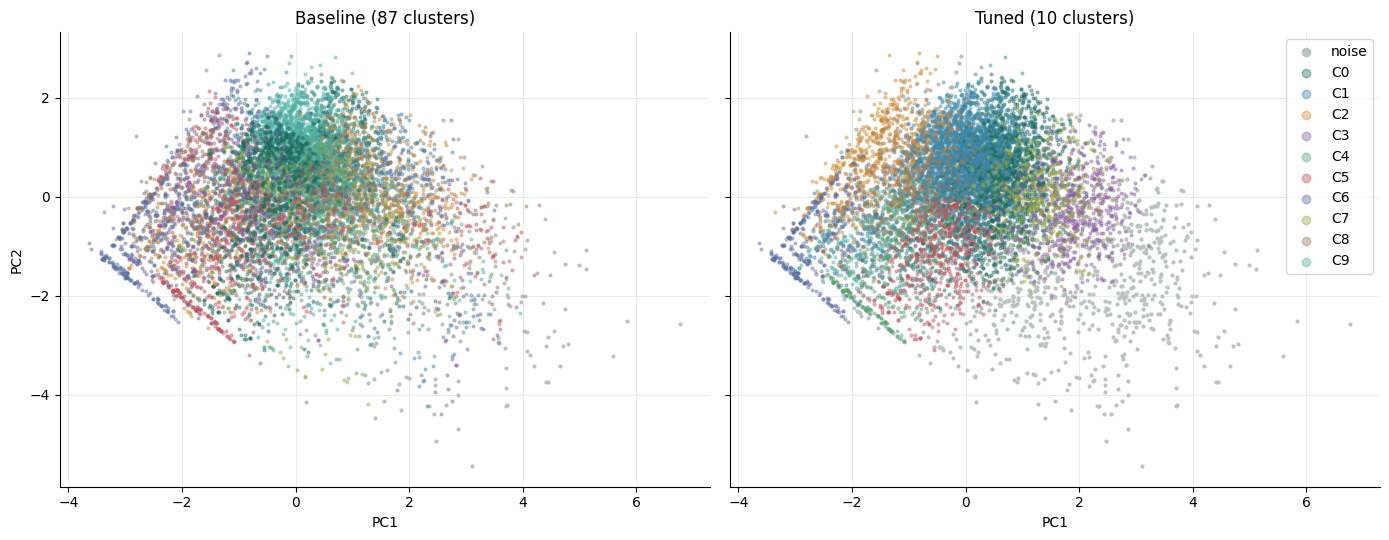

In [ ]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X[S])
print("variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, model_labels, title in [(axes[0], baseline.labels_, "Baseline"), (axes[1], labels, "Tuned")]:
    lab = model_labels[S]
    ax.scatter(P[lab < 0, 0], P[lab < 0, 1], s=4, color=grey, label="noise")
    for k in range(lab.max() + 1):
        ax.scatter(P[lab == k, 0], P[lab == k, 1], s=4, alpha=0.4, color=COLORS[k % len(COLORS)], label=f"C{k}")
    ax.set_title(f"{title} ({model_labels.max() + 1} clusters)")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[1].legend(markerscale=3)
save("05_pca_baseline_vs_tuned.png")

## 9 How the clusters differ from the average booking

Effect size = (cluster mean − overall mean) / overall standard deviation. Positive is above average

In [ ]:
desc = info.copy()
desc["HasChildren"] = ((desc["Children"] + desc["Babies"]) > 0).astype(int)
feats = desc[["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "IsRepeatedGuest", "HasChildren"]]

effect = ((feats.groupby(group).mean() - feats.mean()) / feats.std()).loc[names]
ax = effect.T.plot.barh(figsize=(10, 15), width=0.85, color=COLORS[:len(C)] + [grey], title="Effect size per feature")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%+.2f", fontsize=7, padding=2)   # value at the end of each bar
ax.margins(x=0.1)                                            # room for the labels
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
save("06_effect_sizes.png")

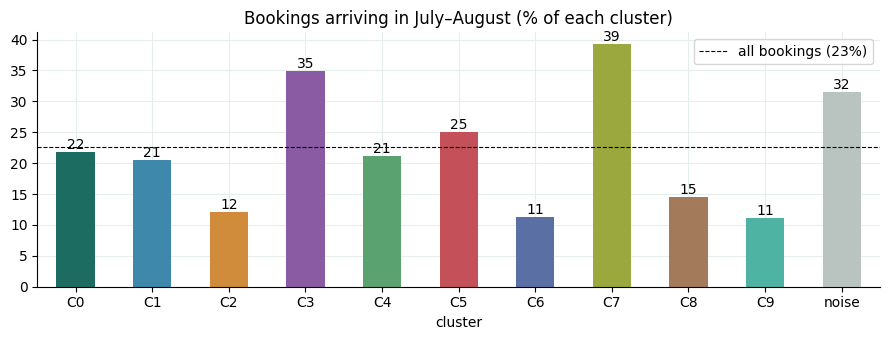

In [ ]:
summer = desc["ArrivalDateMonth"].isin(["July", "August"])
share = summer.groupby(group).mean().loc[names] * 100

ax = share.plot.bar(figsize=(9, 3.5), rot=0, color=COLORS[:len(C)] + [grey], title="Bookings arriving in July–August (% of each cluster)")
ax.bar_label(ax.containers[0], fmt="%.0f")     # value above each bar
ax.axhline(summer.mean() * 100, color="black", ls="--", lw=0.8, label=f"all bookings ({summer.mean() * 100:.0f}%)")
ax.legend(handles=ax.lines)     # only the dashed line
save("07_summer_share.png")

| Cluster | Share | Name | Main traits |
|---|---|---|---|
| C0 | 28.6% | Couples with requests | 2 guests, 3 nights, 63 days ahead, 1.3 requests, mostly Online TA |
| C1 | 25.0% | Couples without requests | like C0 but no requests, a lower price (€96) and much more Offline TA/TO |
| C2 | 7.2% | Solo, no requests | 1 guest, 3 nights, no requests, a mixed channel (Corporate, Groups, Offline TA/TO) |
| C3 | 6.4% | Families with requests | 3 guests, 84 days ahead, €138, 1.6 requests, many children |
| C4 | 4.8% | One-night couples, no requests | 2 guests, 1 night, 11 days ahead, the most Direct bookings |
| C5 | 4.8% | One-night couples with requests | 2 guests, 1 night, 20 days ahead, 1.3 requests |
| C6 | 4.4% | Business travellers | 1 guest, 1 night, 6 days ahead, no requests, the most Corporate, 14.5% repeat guests |
| C7 | 4.1% | Families without requests | 3 guests, 90 days ahead, the highest cluster price (€143), no requests, many children |
| C8 | 3.0% | Solo with requests | 1 guest, 3 nights, 1.1 requests, 13.3% repeat guests |
| C9 | 1.7% | Loyal regulars | 1 guest, 1 night, 7 days ahead, 1.2 requests, the most repeat guests (26.6%) |
| noise | 10.0% | Large, expensive bookings | the highest price (€164), 2.9 guests, the most children |

* Each cluster is one combination of party size (1 / 2 / 3), length of stay (1 night / several) and special requests (none / some).
* The noise is not random: it is the large, expensive bookings, which are too spread out to be dense.
* Children and arrival month were not used to build the clusters, but they still fit: the families (C3, C7) and the noise have the most July–August arrivals, C6 and C9 the fewest.

## 10 leakage audit 

The model is final at this point. `IsCanceled` was not an input and was not used to choose any hyperparameter. It is only looked at here, to check that the clusters are not just a split into "cancels" and "does not cancel" (see the leakage audit in `../preprocessing.ipynb`).

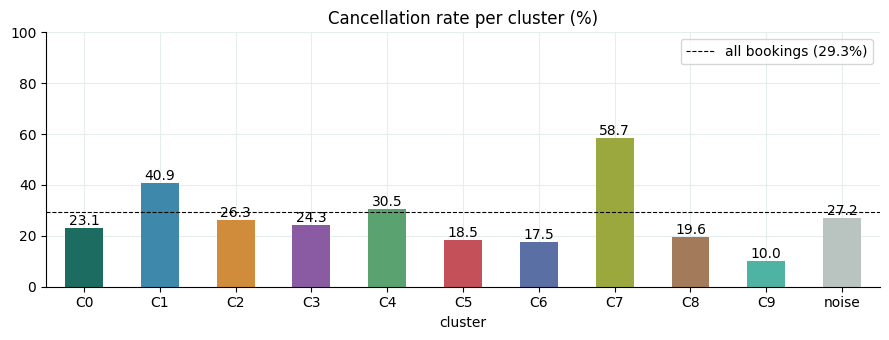

In [ ]:
rate = info.groupby(group)["IsCanceled"].mean().loc[names] * 100
overall = info["IsCanceled"].mean() * 100

ax = rate.plot.bar(figsize=(9, 3.5), rot=0, color=COLORS[:len(C)] + [grey], title="Cancellation rate per cluster (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")     # value above each bar
ax.axhline(overall, color="black", ls="--", lw=0.8, label=f"all bookings ({overall:.1f}%)")
ax.set_ylim(0, 100)
ax.legend(handles=ax.lines)     # only the dashed line
save("08_cancellation.png")

Cancellation ranges from 10.0% (C9) to 58.7% (C7), around 29.3% for all bookings. No cluster is close to 0% or 100%, so the clusters are not a disguised cancellation split and nothing leaked into the inputs.

## Save the tuned model

In [ ]:
joblib.dump(final, f"{MODEL_DIR}/dbscan_tuned.joblib")

['model/dbscan_tuned.joblib']